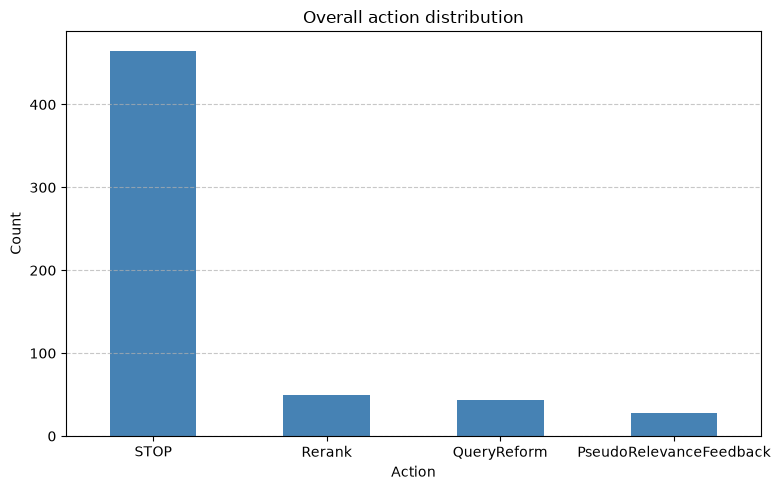

Counts:
action_name
STOP                       465
Rerank                      49
QueryReform                 43
PseudoRelevanceFeedback     28
Name: count, dtype: int64

Frequencies:
action_name
STOP                       0.794872
Rerank                     0.083761
QueryReform                0.073504
PseudoRelevanceFeedback    0.047863
Name: proportion, dtype: float64


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Try repo-root path first, then fall back to the notebooks directory
csv_path = Path("results/expert_boolean_traces_dev2_top20.csv")
if not csv_path.exists():
    csv_path = Path("../results/expert_boolean_traces_dev2_top20.csv")

df = pd.read_csv(csv_path)

# Overall action distribution
action_counts = df["action_name"].value_counts()
action_freq = df["action_name"].value_counts(normalize=True)

plt.figure(figsize=(8, 5))
action_counts.plot(kind="bar", color="steelblue")
plt.title("Overall action distribution")
plt.xlabel("Action")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print("Counts:")
print(action_counts)
print("\nFrequencies:")
print(action_freq)

Action counts by step:
action_name  PseudoRelevanceFeedback  QueryReform  Rerank  STOP
step                                                           
1                                 16           33      25   396
2                                 11            9      21    33
3                                  1            1       3    36


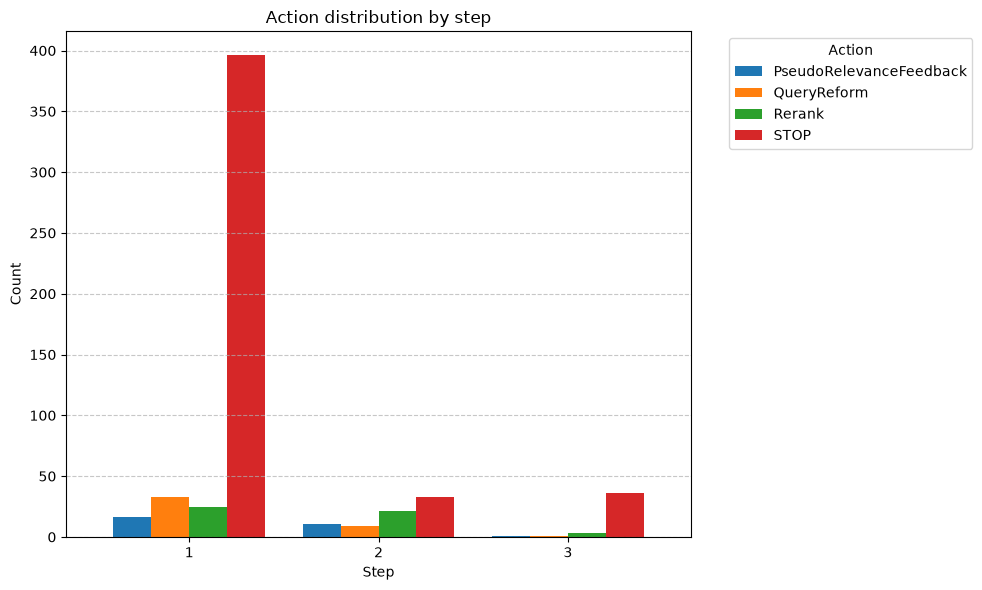

Immediate STOP (step 1): 396
STOP after another action (step > 1): 69


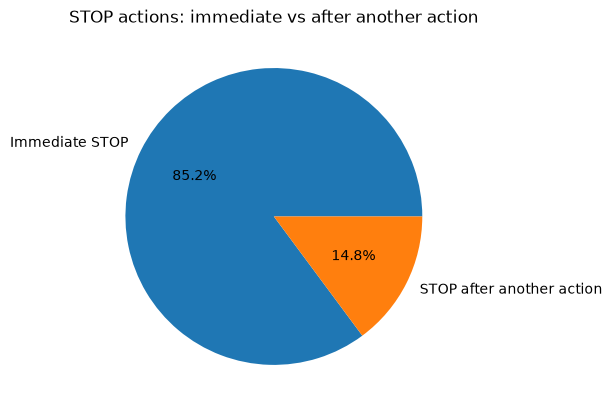

In [2]:
# Differentiate immediate STOP from STOP after another action
step_counts = df.groupby(["step", "action_name"]).size().unstack(fill_value=0)

print("Action counts by step:")
print(step_counts)

# Grouped bar plot by step
ax = step_counts.plot(kind="bar", figsize=(10, 6), width=0.8)
plt.title("Action distribution by step")
plt.xlabel("Step")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.legend(title="Action", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# Immediate STOP vs STOP after another action
stop_step1 = df[(df["action_name"] == "STOP") & (df["step"] == 1)].shape[0]
stop_later = df[(df["action_name"] == "STOP") & (df["step"] > 1)].shape[0]

print(f"Immediate STOP (step 1): {stop_step1}")
print(f"STOP after another action (step > 1): {stop_later}")

# Pie chart of the two STOP categories
stop_categories = pd.Series(
    [stop_step1, stop_later],
    index=["Immediate STOP", "STOP after another action"]
)
stop_categories.plot(kind="pie", autopct="%1.1f%%", figsize=(6, 6))
plt.title("STOP actions: immediate vs after another action")
plt.ylabel("")
plt.tight_layout()
plt.show()

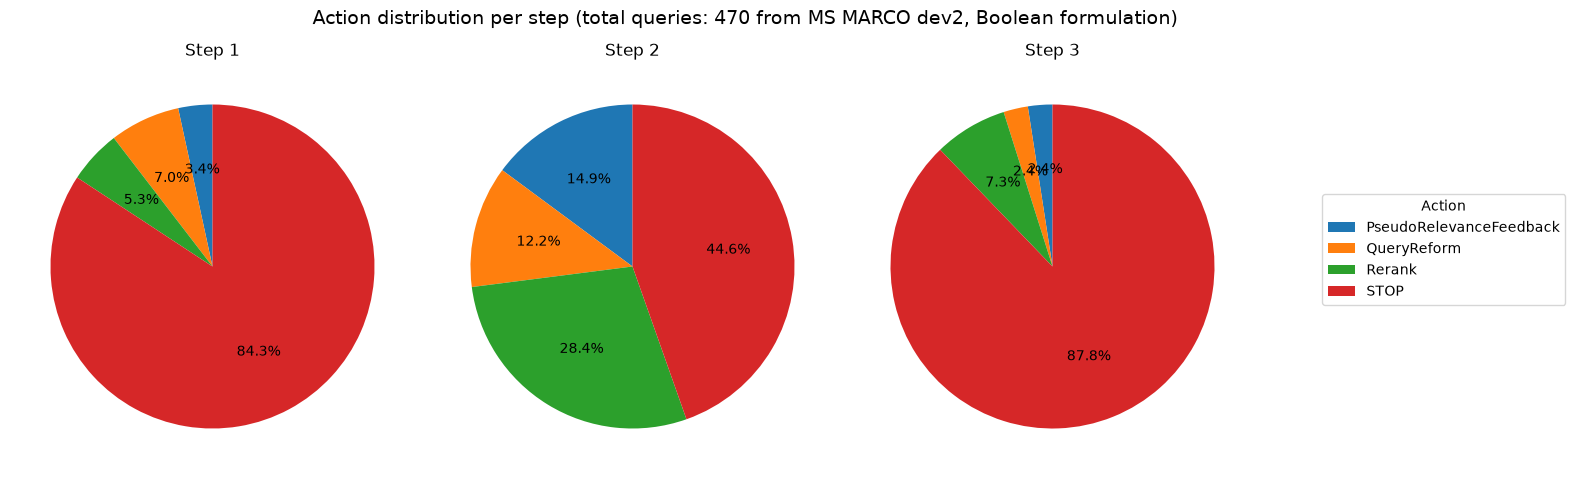

In [4]:
# Pizza (pie) charts showing the action mix at each step
from matplotlib.patches import Patch

actions = sorted(df["action_name"].unique())
colors = plt.cm.tab10.colors[: len(actions)]
color_map = dict(zip(actions, colors))
reform_type = "Boolean formulation"
n_queries = df["query_id"].nunique()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, step in zip(axes, [1, 2, 3]):
    step_df = df[df["step"] == step]
    counts = step_df["action_name"].value_counts().reindex(actions, fill_value=0)
    counts = counts[counts > 0]

    ax.pie(
        counts,
        labels=None,
        autopct="%1.1f%%",
        startangle=90,
        colors=[color_map[a] for a in counts.index],
        pctdistance=0.6,
    )
    ax.set_title(f"Step {step}")

# Single color legend for all three pies
legend_handles = [Patch(facecolor=color_map[a], label=a) for a in actions]
fig.legend(
    handles=legend_handles,
    title="Action",
    loc="center left",
    bbox_to_anchor=(0.88, 0.5),
)

fig.suptitle(
    f"Action distribution per step (total queries: {n_queries} from MS MARCO dev2, {reform_type})",
    fontsize=14,
)
fig.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

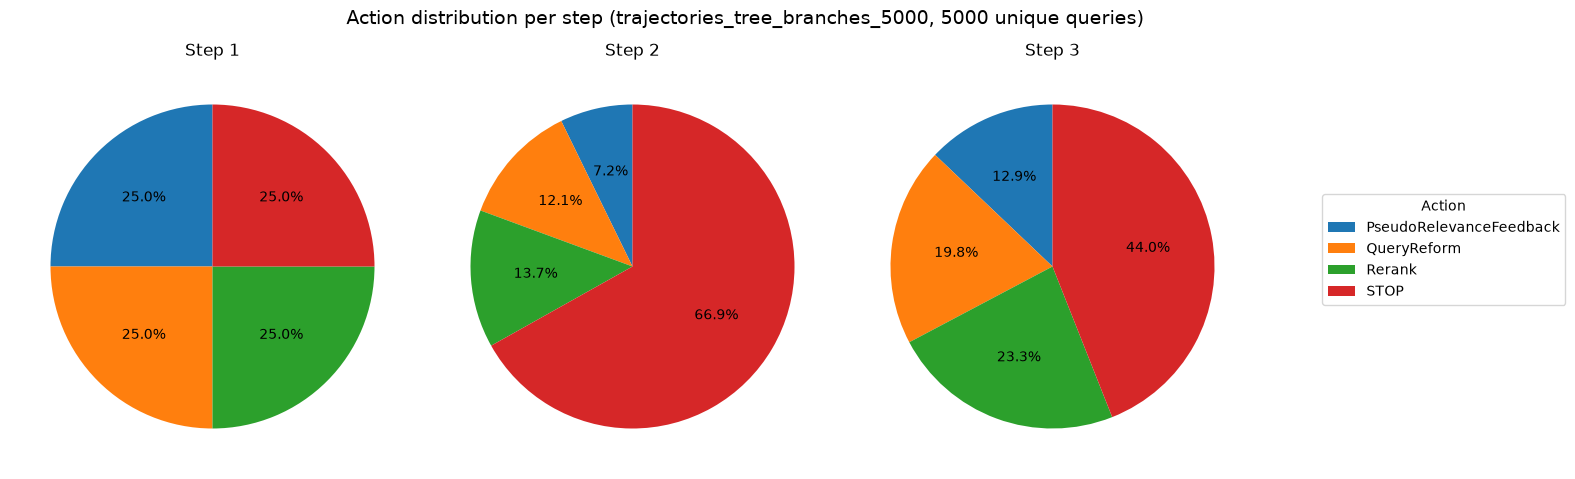

In [ ]:
# Pizza charts for the matching 470 queries in trajectories_expert_5k
from matplotlib.patches import Patch

# Target query IDs from the Boolean traces
target_qids = set(df["query_id"].astype(str))

# Load the expert 5k trajectories
expert5k_path = Path("data/training/trajectories_tree_branches_5000.csv")
if not expert5k_path.exists():
    expert5k_path = Path("../data/training/trajectories_tree_branches_5000.csv")

df5k = pd.read_csv(expert5k_path)
df5k["query_id"] = df5k["query_id"].astype(str)

# Keep only the same 470 queries
# df5k = df5k[df5k["query_id"].isin(target_qids)]

# Map numeric action to names
action_map = {
    0: "QueryReform",
    1: "Rerank",
    2: "PseudoRelevanceFeedback",
    3: "STOP",
}
# df5k["action_name"] = df5k["action"].map(action_map)

# Step values are 0,1,2 in the file; display as 1,2,3
# df5k["step_label"] = df5k["step"] + 1
df5k["step_label"] = df5k["step"] 

actions_5k = sorted(df5k["action_name"].dropna().unique())
colors_5k = plt.cm.tab10.colors[: len(actions_5k)]
color_map_5k = dict(zip(actions_5k, colors_5k))

n_queries_5k = df5k["query_id"].nunique()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, step in zip(axes, [1, 2, 3]):
    step_df = df5k[df5k["step_label"] == step]
    counts = step_df["action_name"].value_counts().reindex(actions_5k, fill_value=0)
    counts = counts[counts > 0]

    ax.pie(
        counts,
        labels=None,
        autopct="%1.1f%%",
        startangle=90,
        colors=[color_map_5k[a] for a in counts.index],
        pctdistance=0.6,
    )
    ax.set_title(f"Step {step}")

legend_handles_5k = [Patch(facecolor=color_map_5k[a], label=a) for a in actions_5k]
fig.legend(
    handles=legend_handles_5k,
    title="Action",
    loc="center left",
    bbox_to_anchor=(0.88, 0.5),
)

fig.suptitle(
    f"Action distribution per step (trajectories_tree_branches_5000, {n_queries_5k} queries)",
    fontsize=14,
)
fig.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

In [1]:
from pathlib import Path
import pandas as pd

# Load the tree-branch trajectories
tree_path = Path("data/training/trajectories_tree_branches_5000.csv")
if not tree_path.exists():
    tree_path = Path("../data/training/trajectories_tree_branches_5000.csv")

df_tree = pd.read_csv(tree_path)

# ------------------------------------------------------------------
# 1. STOP counts
# ------------------------------------------------------------------
stop_rows = (df_tree["action_name"] == "STOP").sum()
print(f"Rows with action STOP: {stop_rows:,}")

# ------------------------------------------------------------------
# 2. Time-limit counts
# ------------------------------------------------------------------
# The query_id column is empty, so we infer trajectories from step resets:
# a new trajectory starts whenever the step number does not increase by 1.
df_tree["trajectory_id"] = (df_tree["step"].diff().fillna(1) <= 0).cumsum()

# The last row of each trajectory tells us how the episode ended.
last_rows = df_tree.groupby("trajectory_id").tail(1)

n_total = len(last_rows)
n_stop_end = (last_rows["action_name"] == "STOP").sum()
n_time_limit = n_total - n_stop_end  # last action was not STOP -> horizon truncation

print(f"\nTotal trajectories: {n_total:,}")
print(f"Trajectories ending with STOP: {n_stop_end:,} ({100 * n_stop_end / n_total:.1f}%)")
print(f"Trajectories ending by time limit (last action != STOP): {n_time_limit:,} ({100 * n_time_limit / n_total:.1f}%)")

# Also report the raw timeout column, in case it is populated
print(f"\nRows with timeout == 1 (raw column): {(df_tree['timeout'] == 1).sum():,}")

Rows with action STOP: 17,216

Total trajectories: 19,999
Trajectories ending with STOP: 17,216 (86.1%)
Trajectories ending by time limit (last action != STOP): 2,783 (13.9%)

Rows with timeout == 1 (raw column): 0
